In [52]:
# Script to simulate DF using fundamental signal components 
# 2026-09-13
# Morena 


using LinearAlgebra
using Plots
using SignalAnalysis
using FFTW

const MIC_NUMBER = 3
const SRCDOA_POINTS = 3
const BASELINE = 0.017 # to avoid spatial aliasing, calculated with fmax=10088kHz, b<=[(c/fmax)/2 = lambda_min/2] 
const C = 343


# Signal simulation
fs = 44100
f = 4000
duration = 3
t = 0:1/fs:duration-1/fs
#theta_pre = rand()*2*(pi)
theta_pre = 22.5*(pi/180)
Fmin = 2000


tau1_21 = (BASELINE*sin((30*(pi/180)-theta_pre)))/C
tau1_31 = (BASELINE*cos(theta_pre))/C


f2 = 6000
f3 = 9500
source1 = sin.(2*pi*f .* t) .+ sin.(2*pi*f2 .* t) .+ sin.(2*pi*f3 .* t)


# Signals received by each microphone

sigMic1 = source1 .+ 0.01 .* randn(size(source1))
sigMic2 = sin.(2*pi*f .* (t .- tau1_21)) .+ 0.01 .* randn(size(source1))
sigMic3 = sin.(2*pi*f .* (t .- tau1_31)) .+ 0.01 .* randn(size(source1))


# Mic position set
mic = [zeros(MIC_NUMBER) for _ in 1:2]
mic[1][1] =  BASELINE/2
mic[1][3] = -BASELINE/2
mic[2][1] = -BASELINE*sqrt(3)/6
mic[2][2] =  BASELINE*sqrt(3)/3
mic[2][3] = -BASELINE*sqrt(3)/6

p1 = [mic[1][1], mic[2][1]]
p2 = [mic[1][2], mic[2][2]]
p3 = [mic[1][3], mic[2][3]]



@show theta_pre*(180/pi)

theta_pre * (180 / pi) = 22.5


22.5

In [53]:
# Signal processing assuming the signals are not known
# BROADBAND SIGNIFICANT PARAMETERs
Frame_len = 1024
Hop = div(Frame_len, 2)
Ns = length(sigMic1)
win = 0.5 .- 0.5 .* cos.(2π .* (0:Frame_len-1) ./ Frame_len)
Nf = 1 + div(Ns - Frame_len, Hop)
nb = div(Frame_len, 2) + 1
freqs = (0:nb-1) .* (fs / Frame_len)
inband = findall(j -> Fmin <= freqs[j] <= f, 1:nb)


# Frame analysis
theta_estimates = Float64[]

for i in 1:Nf
    idx = (i-1)*Hop .+ (1:Frame_len)
    S1f = rfft(win .* sigMic1[idx])
    S2f = rfft(win .* sigMic2[idx])
    S3f = rfft(win .* sigMic3[idx])

    # find the strongest in-band bin for THIS frame
    energies = abs2.(S1f[inband])
    _, local_idx = findmax(energies)
    b = inband[local_idx]

    sigf = freqs[b]
    lambda = C/sigf

    phaseD12 = angle(S2f[b]*conj(S1f[b]))
    phaseD13 = angle(S3f[b]*conj(S1f[b]))

    c = clamp((-phaseD13 * lambda) / (2π * BASELINE), -1, 1)
    s = clamp((-phaseD12 * lambda) / (2π * BASELINE), -1, 1)
    sin_theta = (c - 2s) / sqrt(3)

    theta_frame = mod(atan(sin_theta, c), 2*pi)
    push!(theta_estimates, theta_frame)
end

# Circular mean/median across frames to avoid angles wrapping
sin_mean = mean(sin.(theta_estimates))
cos_mean = mean(cos.(theta_estimates))
theta_Calc = mod(atan(sin_mean, cos_mean), 2*pi)
@show theta_Calc*(180/pi)


theta_Calc * (180 / pi) = 22.498761574931727


22.498761574931727

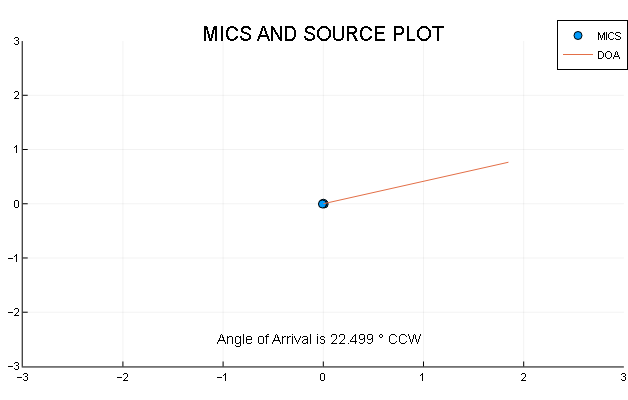

In [54]:
# Plot of the mics and the direction of arrival of the signal

plotly()

srcDOA = [zeros(SRCDOA_POINTS) for _ in 1:2]
for i in 1:SRCDOA_POINTS
    r = i-1
    srcDOA[1][i] =r*cos(theta_Calc)
    srcDOA[2][i] =r*sin(theta_Calc)
end

scatter(mic[1], mic[2], xlims=(-3, 3), ylims=(-3, 3), title="MICS AND SOURCE PLOT", label = "MICS")
aoaDF = round(theta_Calc* (180/pi), digits = 3)
plot!(srcDOA[1], srcDOA[2], label = "DOA")
aoa = text("Angle of Arrival is $aoaDF ° CCW", :black, :right, 10)
annotate!(1, -2.5, aoa)